**UNIFORM COST SEARCH - TRAILER ROUTE OPTIMIZATION**

* The highway network is represented as a directed, weighted graph.
* Cities and Towns represent nodes (states), while highway connections represent directed edges (actions).
* The distance between towns is used as path cost.
* Uniform Cost Search is applied to explore the network and identify the route with the minimum cumulative travel distance.




**PROBLEM FORMULATION**

| Component | Description |
|---|---|
| Initial State | Nairobi |
| Goal State | Kisumu |
| State Space | The 14 cities and towns in the highway network |
| Actions | Travelling along an available highway connection |
| Transition Model | Moving from one town to an adjacent town |
| Path Cost | Cumulative distance travelled in kilometres |
| Search Strategy | Uniform Cost Search |



In [17]:
import heapq
import itertools
import networkx as nx
import matplotlib.pyplot as plt

In [18]:
# Create a directed graph
G = nx.DiGraph()

# Define the towns in the highway network
towns = [
    "Nairobi",
    "Thika",
    "Nyeri",
    "Karatina",
    "Nanyuki",
    "Naivasha",
    "Nakuru",
    "Eldoret",
    "Narok",
    "Bomet",
    "Kericho",
    "Kakamega",
    "Kisumu",
    "Siaya"
]

# Add all towns as nodes
G.add_nodes_from(towns)

# Define directed highway connections and distances (km)
roads = [
    ("Nairobi", "Thika", 45),
    ("Thika", "Nyeri", 120),
    ("Nyeri", "Karatina", 70),
    ("Karatina", "Nanyuki", 70),

    ("Nairobi", "Naivasha", 89),
    ("Naivasha", "Nakuru", 76),
    ("Nakuru", "Kericho", 105),
    ("Kericho", "Kisumu", 100),

    ("Nakuru", "Eldoret", 160),
    ("Eldoret", "Kakamega", 100),
    ("Kakamega", "Kisumu", 50),

    ("Nairobi", "Narok", 140),
    ("Narok", "Bomet", 100),
    ("Bomet", "Kericho", 50)
]

# Add each road in both directions
for source, destination, distance in roads:
    G.add_edge(source, destination, weight=distance)
    G.add_edge(destination, source, weight=distance)

print("Directed Highway Network Created Successfully")
print("Number of towns:", G.number_of_nodes())
print("Number of directed connections:", G.number_of_edges())

Directed Highway Network Created Successfully
Number of towns: 14
Number of directed connections: 28


**VISUALIZE HIGHWAY NETWORK**

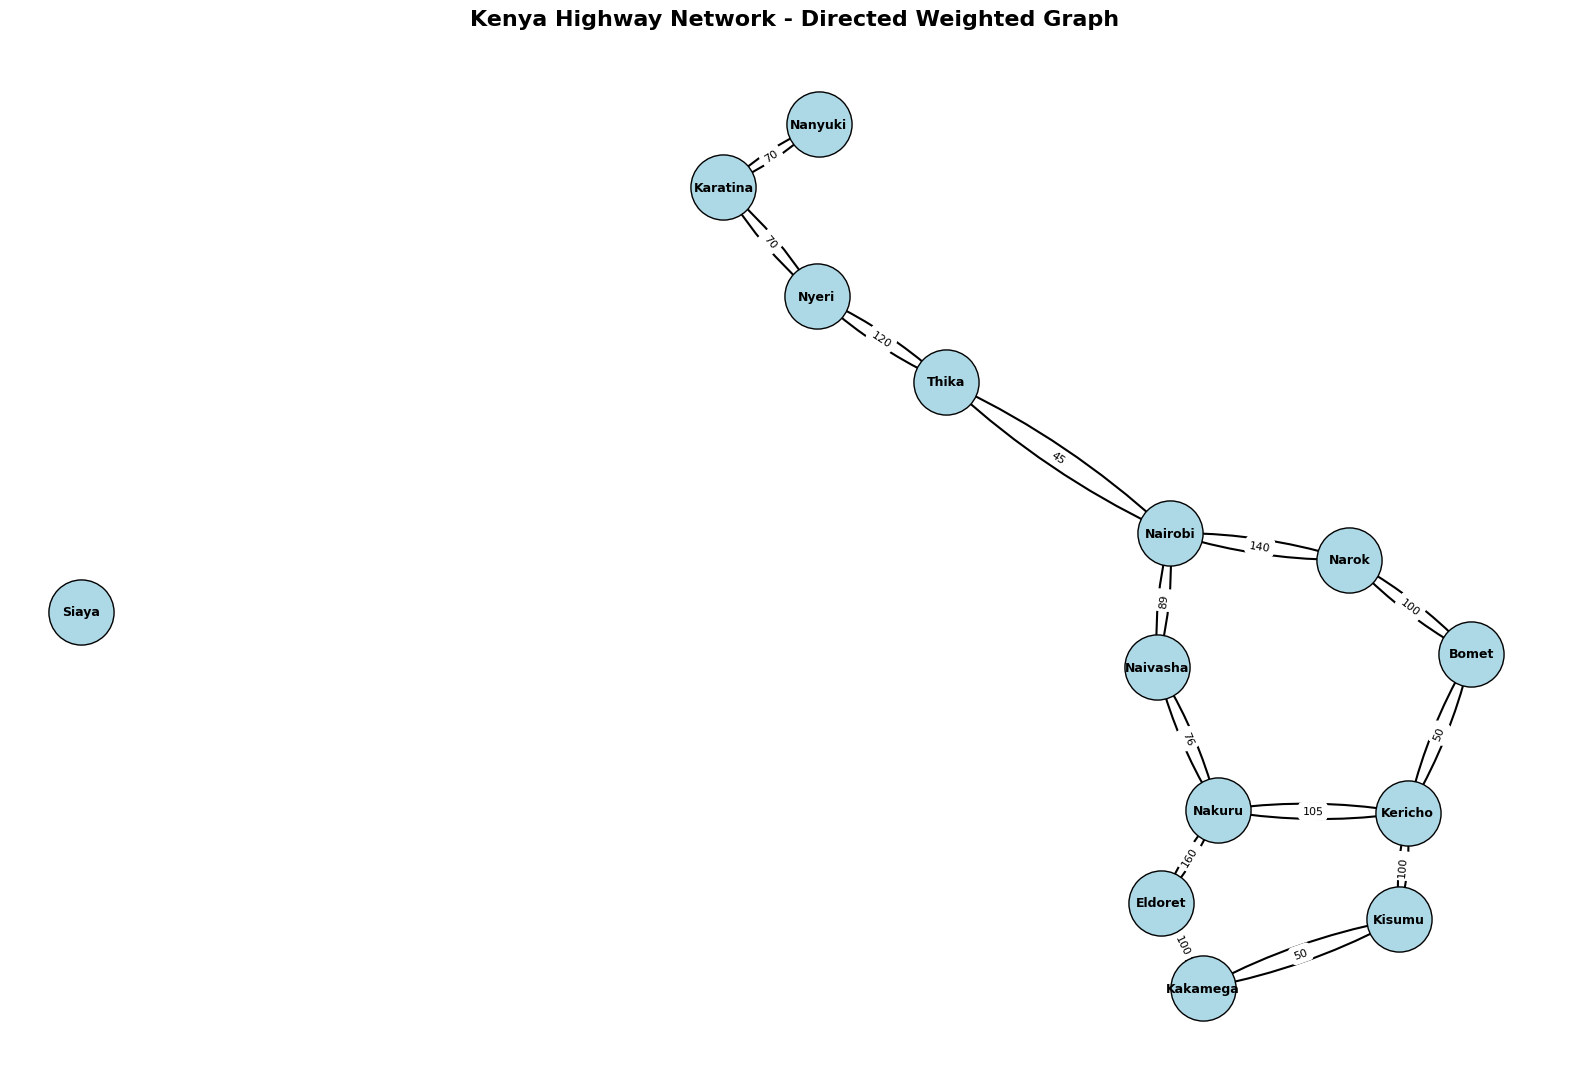

In [19]:
plt.figure(figsize=(16, 11))

# Generate node positions
pos = nx.spring_layout(G, seed=42, k=1.5)

# Draw nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=2200,
    node_color="lightblue",
    edgecolors="black"
)

# Draw node labels
nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_weight="bold"
)

# Draw directed edges
nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=18,
    connectionstyle="arc3,rad=0.08",
    width=1.5
)

# Draw edge weights
edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8,
    label_pos=0.5
)

plt.title(
    "Kenya Highway Network - Directed Weighted Graph",
    fontsize=16,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

**UNIFORM COST SEARCH ALGORITHM**

* Initialize a priority queue with the starting node, Nairobi, at a cost of zero.

* Remove the node with the lowest cumulative cost from the priority queue.

* Check whether the removed node is the goal state, Kisumu.

* If it is not the goal, expand its neighbouring nodes.

* Calculate the new cumulative cost for each neighbour.

* Add a neighbour to the priority queue if a cheaper route to it has been found.

* Repeat the process until Kisumu is reached or the frontier becomes empty.

* Reconstruct the optimal path using the recorded parent nodes.



**IMPLEMENT UNIFORM COST SEARCH**

In [20]:
def uniform_cost_search(graph, start, goal):

    # Counter ensures that equal-cost entries can be compared safely
    counter = itertools.count()

    # Priority queue: (cumulative cost, counter, current node)
    frontier = [(0, next(counter), start)]

    # Stores the lowest known cost to reach each node
    best_cost = {start: 0}

    # Stores the parent of each node for path reconstruction
    parent = {start: None}

    # Stores expanded nodes
    explored = []

    # Stores search steps for demonstration
    search_steps = []

    while frontier:

        # Remove the node with the lowest cumulative cost
        current_cost, _, current_node = heapq.heappop(frontier)

        # Ignore outdated entries in the priority queue
        if current_cost > best_cost[current_node]:
            continue

        # Record the expanded node
        explored.append(current_node)

        # Check if the goal has been reached
        if current_node == goal:
            break

        # Expand neighbouring nodes
        for neighbor in graph.successors(current_node):

            # Get the distance between current node and neighbour
            edge_cost = graph[current_node][neighbor]["weight"]

            # Calculate the new cumulative path cost
            new_cost = current_cost + edge_cost

            # Update only if a cheaper route is found
            if new_cost < best_cost.get(neighbor, float("inf")):

                best_cost[neighbor] = new_cost
                parent[neighbor] = current_node

                # Add the neighbour to the priority queue
                heapq.heappush(
                    frontier,
                    (new_cost, next(counter), neighbor)
                )

        # Record the current search step
        frontier_snapshot = sorted(
            [(cost, node) for cost, _, node in frontier]
        )

        search_steps.append({
            "expanded": current_node,
            "cost": current_cost,
            "frontier": frontier_snapshot.copy()
        })

    # If the goal cannot be reached
    if goal not in best_cost:
        return None, float("inf"), explored, search_steps, parent

    # Reconstruct the optimal path
    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = parent[node]

    path.reverse()

    # Return the results
    return path, best_cost[goal], explored, search_steps, parent

**EXECUTE THE SEARCH**

In [21]:
# Define the initial and goal states
start = "Nairobi"
goal = "Kisumu"

# Execute Uniform Cost Search
optimal_path, total_cost, explored_nodes, search_steps, parent = (
    uniform_cost_search(G, start, goal)
)

print("UNIFORM COST SEARCH EXECUTION")
print("=" * 50)

print("Initial State:", start)
print("Goal State:", goal)

print("\nNODE EXPANSION AND FRONTIER DETAILS")
print("=" * 50)

for step_number, step in enumerate(search_steps, start=1):

    print(f"\nStep {step_number}")
    print("Expanded Node:", step["expanded"])
    print("Cumulative Cost:", step["cost"], "km")

    print("Frontier:")

    for cost, node in step["frontier"]:
        print(f"  {node}: {cost} km")

print("\n" + "=" * 50)

print("ORDER OF EXPANSION:")
print(" -> ".join(explored_nodes))

print("\nOPTIMAL PATH:")
print(" -> ".join(optimal_path))

print("\nTOTAL PATH COST:", total_cost, "km")

UNIFORM COST SEARCH EXECUTION
Initial State: Nairobi
Goal State: Kisumu

NODE EXPANSION AND FRONTIER DETAILS

Step 1
Expanded Node: Nairobi
Cumulative Cost: 0 km
Frontier:
  Thika: 45 km
  Naivasha: 89 km
  Narok: 140 km

Step 2
Expanded Node: Thika
Cumulative Cost: 45 km
Frontier:
  Naivasha: 89 km
  Narok: 140 km
  Nyeri: 165 km

Step 3
Expanded Node: Naivasha
Cumulative Cost: 89 km
Frontier:
  Narok: 140 km
  Nakuru: 165 km
  Nyeri: 165 km

Step 4
Expanded Node: Narok
Cumulative Cost: 140 km
Frontier:
  Nakuru: 165 km
  Nyeri: 165 km
  Bomet: 240 km

Step 5
Expanded Node: Nyeri
Cumulative Cost: 165 km
Frontier:
  Nakuru: 165 km
  Karatina: 235 km
  Bomet: 240 km

Step 6
Expanded Node: Nakuru
Cumulative Cost: 165 km
Frontier:
  Karatina: 235 km
  Bomet: 240 km
  Kericho: 270 km
  Eldoret: 325 km

Step 7
Expanded Node: Karatina
Cumulative Cost: 235 km
Frontier:
  Bomet: 240 km
  Kericho: 270 km
  Nanyuki: 305 km
  Eldoret: 325 km

Step 8
Expanded Node: Bomet
Cumulative Cost: 240 km
Fr

**DISPLAY OPTIMAL PATH AND PATH COST CALCULATION**

In [22]:
print("OPTIMAL TRAILER ROUTE")
print("=" * 45)

for i in range(len(optimal_path) - 1):

    source = optimal_path[i]
    destination = optimal_path[i + 1]

    distance = G[source][destination]["weight"]

    print(f"{source} -> {destination}: {distance} km")

print("-" * 45)

print("Route:", " -> ".join(optimal_path))
print("Total Distance:", total_cost, "km")

OPTIMAL TRAILER ROUTE
Nairobi -> Naivasha: 89 km
Naivasha -> Nakuru: 76 km
Nakuru -> Kericho: 105 km
Kericho -> Kisumu: 100 km
---------------------------------------------
Route: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Total Distance: 370 km


**VISUALIZE OPTIMAL ROUTE**

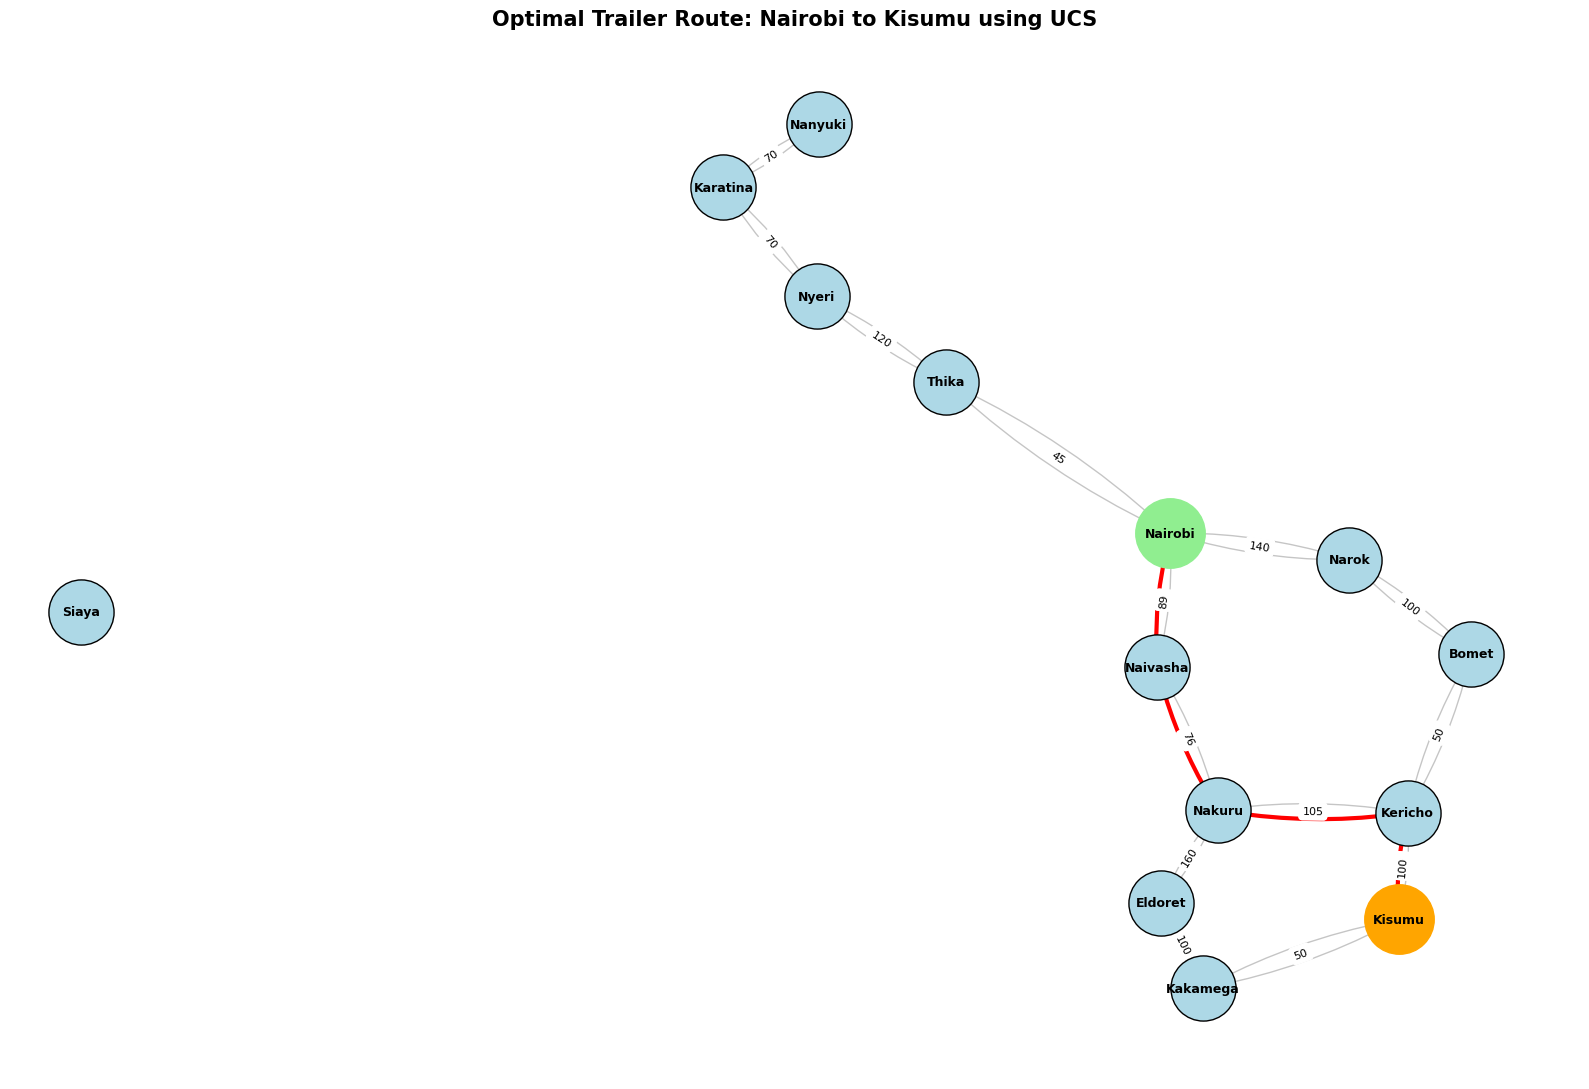

In [23]:
# Create a list of edges belonging to the optimal path
optimal_edges = list(zip(optimal_path, optimal_path[1:]))

plt.figure(figsize=(16, 11))

pos = nx.spring_layout(G, seed=42, k=1.5)

# Draw all nodes
nx.draw_networkx_nodes(
    G, pos,
    node_size=2200,
    node_color="lightblue",
    edgecolors="black"
)

# Highlight the starting and goal nodes
nx.draw_networkx_nodes(
    G, pos,
    nodelist=["Nairobi"],
    node_color="lightgreen",
    node_size=2500
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=["Kisumu"],
    node_color="orange",
    node_size=2500
)

# Draw all edges
nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=18,
    edge_color="gray",
    alpha=0.45,
    connectionstyle="arc3,rad=0.08"
)

# Highlight the optimal path
nx.draw_networkx_edges(
    G, pos,
    edgelist=optimal_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=22,
    connectionstyle="arc3,rad=0.08"
)

# Draw labels
nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_weight="bold"
)

# Draw edge weights
edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    "Optimal Trailer Route: Nairobi to Kisumu using UCS",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

**SEARCH TREE REPRESENTATION**

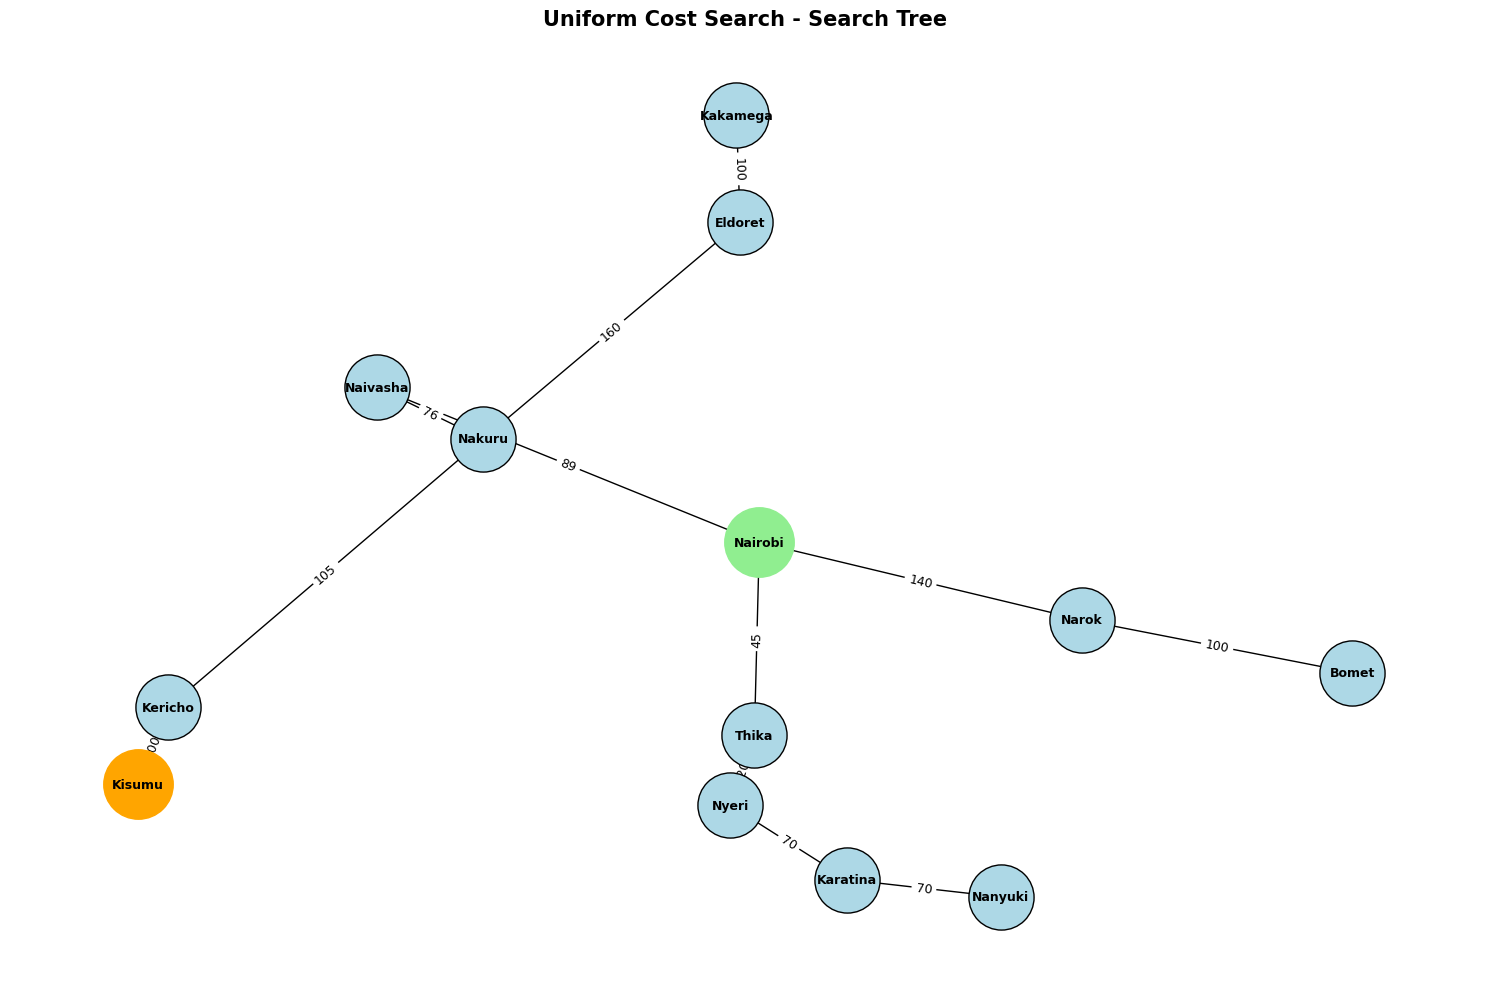

In [24]:
# Create a separate directed search tree
search_tree = nx.DiGraph()

# Add the starting node
search_tree.add_node(start)

# Add parent-child relationships
for child, par in parent.items():
    if par is not None:
        search_tree.add_edge(
            par,
            child,
            weight=G[par][child]["weight"]
        )

# Generate tree positions
tree_pos = nx.spring_layout(
    search_tree,
    seed=42,
    k=1.5
)

plt.figure(figsize=(15, 10))

# Draw tree nodes
nx.draw_networkx_nodes(
    search_tree,
    tree_pos,
    node_size=2200,
    node_color="lightblue",
    edgecolors="black"
)

# Highlight start and goal
nx.draw_networkx_nodes(
    search_tree,
    tree_pos,
    nodelist=[start],
    node_color="lightgreen",
    node_size=2500
)

if goal in search_tree:
    nx.draw_networkx_nodes(
        search_tree,
        tree_pos,
        nodelist=[goal],
        node_color="orange",
        node_size=2500
    )

# Draw directed tree edges
nx.draw_networkx_edges(
    search_tree,
    tree_pos,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20
)

# Draw labels
nx.draw_networkx_labels(
    search_tree,
    tree_pos,
    font_size=9,
    font_weight="bold"
)

# Display edge costs
tree_labels = nx.get_edge_attributes(
    search_tree, "weight"
)

nx.draw_networkx_edge_labels(
    search_tree,
    tree_pos,
    edge_labels=tree_labels,
    font_size=9
)

plt.title(
    "Uniform Cost Search - Search Tree",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

**VERIFY FINAL PATH COST**

In [25]:
# Independently calculate the total distance
calculated_cost = sum(
    G[optimal_path[i]][optimal_path[i + 1]]["weight"]
    for i in range(len(optimal_path) - 1)
)

print("PATH COST VERIFICATION")
print("=" * 40)

print("UCS Reported Cost:", total_cost, "km")
print("Calculated Path Cost:", calculated_cost, "km")

if calculated_cost == total_cost:
    print("VERIFICATION: PASSED")
else:
    print("VERIFICATION: FAILED")

print("Number of towns in optimal path:", len(optimal_path))
print("Number of nodes expanded:", len(explored_nodes))

PATH COST VERIFICATION
UCS Reported Cost: 370 km
Calculated Path Cost: 370 km
VERIFICATION: PASSED
Number of towns in optimal path: 5
Number of nodes expanded: 12


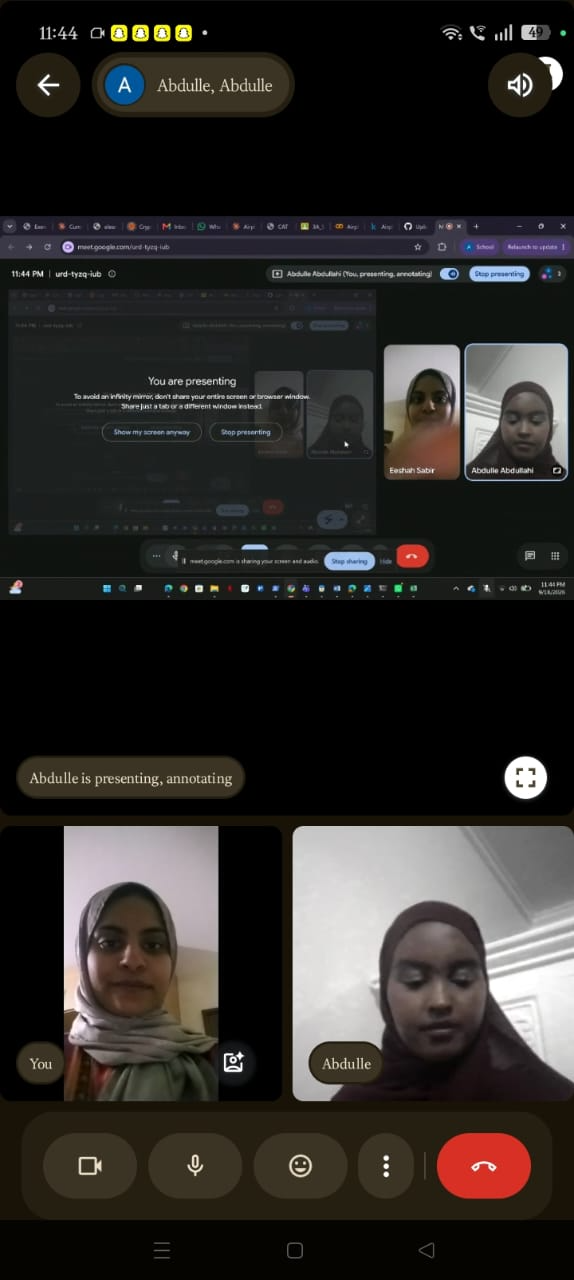